# Solutions - Stat 371 Practice Problem Session #5
---

TAs: Zach LeClaire, Lanxi Zhang. If you have any questions after the session, contact us at zleclaire@wisc.edu and lzhang699@wisc.edu

Today's Topics: 
1. Sampling Distributions  
2. Central Limit Theorem

1. Sampling Distributions

One of the harder concepts in statistics is that of the sampling distribution. 

a. What do we mean by a "sampling distribution"? Come up with an example involving binomial random variables, making sure to identify the parameter of interest and what the sampling distribution could look like.

Sol. 

A basketball team made up of clones of Stephen Curry all shoot freethows with the same probability p. If we assume there are 30 free throws in a game, then the average number of throws made in the game is 30 * p. The sample proportion of throws would be our estimator here and it would be a binomial distribution with mean p and variance $\frac{p(1-p)}{n}$. 

b. What does the Central Limit Theorem (CLT) say about the sampling distribution for sample mean / sample proportion? Use this to say something about your example from part (a).

Sol. 

The CLT says that our sampling distribution would be approximately normal if there are a large number of free throws in the game.

c. Why might it be helpful to study the distribution of a sample mean / proportion? What can it tell us about our problem? (come back to this at the end if you aren't sure yet. These problems will you show you some applications) 

2. Typical Coin Counts

Recall the central limit theorem: If $\bar{X} \sim_{approx} N(\mu, (\sigma/\sqrt{n})^2)$ where $se = \sigma/\sqrt{n}$ is called the standard error

a. First we'll seem some examples of the CLT in action. The "rbinom" function samples randomly and independently from the binomial distribution. Try running the code below for N = 10, 100, 1000, 10000. Explain what's happening to the sampling distribution as your sample size N grows bigger. Interpret this if we think about this in the case of flipping a biased coin.

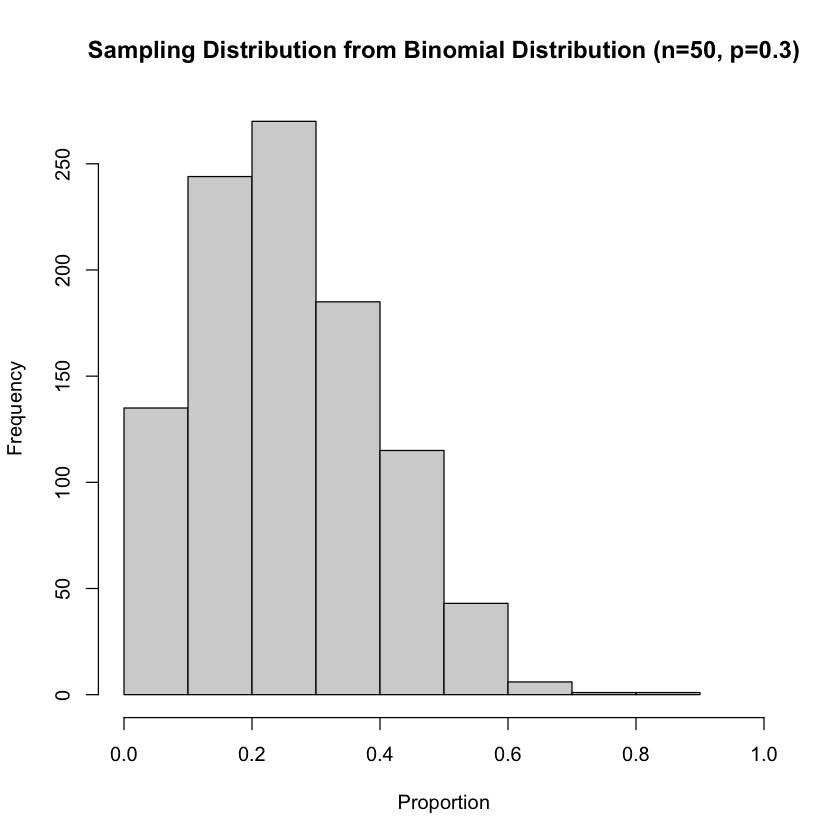

In [1]:
N = 10
samples <- rbinom(n = 1000, size = N, prob = 0.3)/N
hist(samples, main = "Sampling Distribution from Binomial Distribution (n=50, p=0.3)", xlab = "Proportion", xlim = c(0, 1))

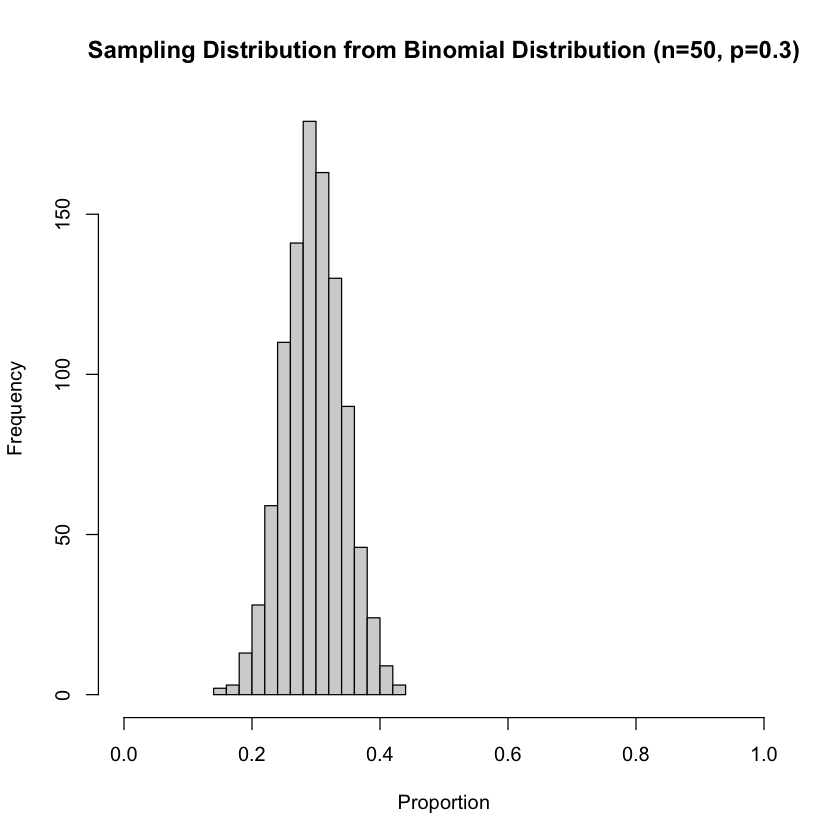

In [2]:
N = 100
samples <- rbinom(n = 1000, size = N, prob = 0.3)/N
hist(samples, main = "Sampling Distribution from Binomial Distribution (n=50, p=0.3)", xlab = "Proportion", xlim = c(0, 1))

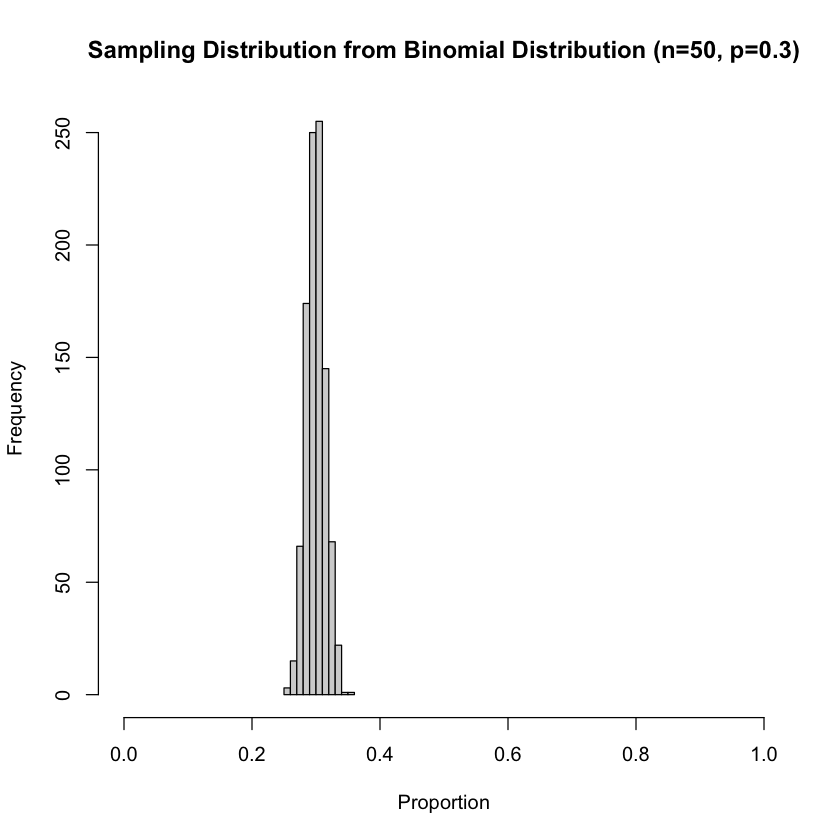

In [3]:
N = 1000
samples <- rbinom(n = 1000, size = N, prob = 0.3)/N
hist(samples, main = "Sampling Distribution from Binomial Distribution (n=50, p=0.3)", xlab = "Proportion", xlim = c(0, 1))

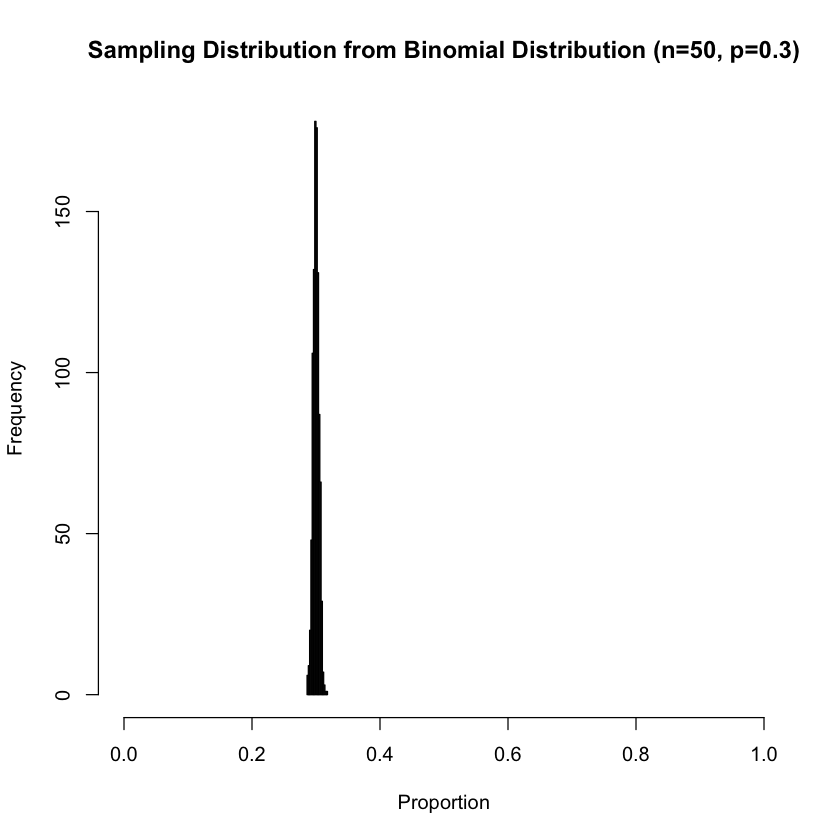

In [4]:
N = 10000
samples <- rbinom(n = 1000, size = N, prob = 0.3)/N
hist(samples, main = "Sampling Distribution from Binomial Distribution (n=50, p=0.3)", xlab = "Proportion", xlim = c(0, 1))

Notice how the sampling distribution becomes symmetrized AND shrinks towards the mean. This is because the variance of the sample mean is sigma^2 / n, so as n gets bigger the variance shrinks.

b. Describe the distribution of the number of heads from flipping 10, 100, 500, and 1000 flips of a *fair* coin. Plot the histograms of the sample proporition of heads for N = 1000 expirements for each of the four scenarios describes above.

Sol. 

Bin(N, 0.5) for N = 10,100, 500, 1000

Just modify the code above by using the right probablity p, the right N, and different title/axis names. 

c. Re-run the code above with p=0.1 and compare the results with the histograms from previous part. What distribution do these histograms resemble? 

Sol. 

They all limit towards normal distributions / bell curves!

d. This is a neat observation, but why should anyone care? If we know the distribution of our sample proportion/mean, then we can say things about the likelyhood of seeing certain values!

Sol. 

We care because we can use probability to learn about our problem. For example, we can 

Use the CLT to approximate the probability that you'll see more than 550 heads from 1000 flips of a fair coin. Compare the results to the exact calculations using pbinom()


In [17]:
zscore = (0.55-0.5)/(sqrt(0.5*(1-0.5)/1000))
1-pnorm(zscore)

[1] 0.0007827011

In [19]:
1-pbinom(550, 1000, 0.5)

[1] 0.0006958708

That's pretty unlikely!!

e. One of the reasons we care so much about the CLT is because it helps us doing hypothesis testing. Suppose you want to test whether a coin is fair. The way we construct hypothesis tests is we determine 'extreme' head counts that would be exceedingly unlikely. 

Use qnorm to find the number of heads $H$ such that $P(\text{\# Heads Observed} \geq H) \leq 0.001$. Compare the result to the exact value using qbinom(). If we 'reject' the hypothesis that a coin is fair when it's above this number of heads, would we flag a head count of 550?   

Sol. 

In [25]:
zscore = qnorm(1-0.001)
Head_proportion = 0.5 + zscore * (sqrt(0.5*(1-0.5)/1000))
Head_proportion * 1000

[1] 548.8609

In [28]:
qbinom(0.999, 1000, 0.5)

[1] 549

We would flag that a coin flipped 550 times is biased.

3. White Nile Frogs  

Some scientists are collecting data on the dimensions of the Xenopus (African clawed frog) from the White Nile River. The scientists collect the following data describing the lengths of the frogs: 

15, 19, 8, 12, 16, 12, 14, 12, 14, 13, 15, 12, 9, 17, 18, 20, 12, 15, 18, 21, 8, 10, 12, 14, 17, 18, 20, 20, 21, 11, 12, 17, 18, 19, 20, 21, 9, 11, 10, 10, 11, 12, 14, 14, 19, 10, 9, 11, 16, 9, 8, 10, 11, 12

a. Calculate the the sample mean and standard error of frog sizes. 

b. Use the CLT to describe the approximate distribution of the sample mean. 

c. Use this approximate distribution to estimate the probability that $P(10 \leq \bar X \leq 20)$

d. Some locals claim the frogs in the While Nile are smaller than those in a nearby pond. The scientists conduct a census of the small pond and find that the mean length of frogs in that pond is exactly 20.78 cm. What's $P(\bar X > 18)$? Does the claim of the locals seem reasonable?

In [31]:
frog_data = c(15, 19, 8, 12, 16, 12, 14, 12, 14, 13, 15, 12, 9, 17, 18, 20, 12, 15, 18, 21, 8, 10, 12, 14, 17, 18, 20, 20, 21, 11, 12, 17, 18, 19, 20, 21, 9, 11, 10, 10, 11, 12, 14, 14, 19, 10, 9, 11, 16, 9, 8, 10, 11, 12)
mean(frog_data)
sd(frog_data)/sqrt(length(frog_data))

[1] 14

[1] 0.541112

b. 
$\bar X \sim_{approx} N(14, 0.541 ^2)$ by CLT

c. 
$P(13 \leq \bar X \leq 17) = P(X \leq 17)-P(X \leq 13)$

In [33]:
pnorm(17,mean = 14, sd = 0.541) - pnorm(13,mean = 14, sd = 0.541)

[1] 0.9677298

So, if we repeated the expirement again, there would be a 96.7% that the sample mean is inside this interval. This is what we call a "Confidence interval" and it gives us a sense of how accurate our estimate is.

d.

In [39]:
pnorm(18,mean = 14, sd = 0.541)

[1] 1

The locals seem to be correct! There is a 18

4. Painting the big picture

Two important big picture ideas about statistics and probability are listed below along with a graphical representation. For each statement, describe a *different* example scenario involving binomial random variables (instead of normal random variables) that emphasizes the point of the statement. 

a. Probability theory describes how likely we will see quantities of samples (like averages or proportions) in random samples of a population given an underlying distribution. For example, if we know that crab claw length is approximately normally distributed with $\mu = 5, \sigma^2 = 1$, then the 68-95-99.7 rule tells us that we will see very few (0.03%) crabs with claw length over 3 standard deviations away from $\mu$, or $\mu \pm 3 * \sigma = 2,8$. 

b. Statistics is the reverse problem: it studies how we can learn about the underlying distribution of the population given a sample. For example, if we know that crab claw lengths are approximately normally distributed, then we can just try to estimate the mean and standard deviation to describe the distribution of crabs.

![SNOWFALL](ProbStatsGraphic.png)